In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

 layer  min_rank_for_50pct_energy  energy_at_rank_16 (%)  energy_at_rank_64 (%)  energy_at_rank_256 (%)  sigma_1_energy_share (%)
     0                         62              34.767456              50.635212               76.352547                 17.241911
     1                        174              13.377852              28.368647               61.109715                  4.998403
     2                        184              11.681294              27.860752               59.357025                  3.617149
     3                        172              13.178960              28.821463               61.076843                  4.143298
     4                        162              13.634600              29.926020               62.781368                  4.277883
     5                        144              13.850861              31.542978               66.694389                  4.191604
     6                        139              15.491592              33.245583           

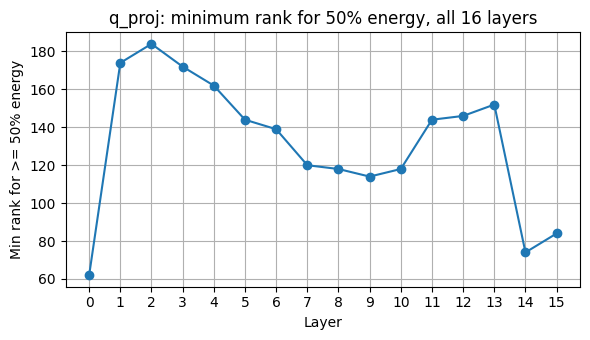

In [5]:
# Extra analysis (NOT required by the assignment):
# Q4 only looks at layers 0/7/15. Here we repeat the same q_proj SVD for all 16 layers
# to check whether "layer 7 is the most spread-out" is a depth trend or a one-off.
# Run it as a new cell in finetune_q4.ipynb after `model` is loaded (cell 1),
# or as a script: it loads the model itself if `model` is not defined.
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

if 'model' not in globals():
    from transformers import AutoModelForCausalLM
    model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B')

THRESHOLD = 50.0  # same 50% cumulative-energy criterion as Q4b
OUT_DIR = Path('/kaggle/working/Assignment1_q4') if Path('/kaggle').exists() else Path('Assignment1_q4')
OUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []
for k, layer in enumerate(model.model.layers):
    W = layer.self_attn.q_proj.weight.detach().float()
    S = torch.linalg.svdvals(W)                       # singular values only, sorted descending
    E = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
    rows.append({
        'layer': k,
        'min_rank_for_50pct_energy': int((E >= THRESHOLD).nonzero()[0].item()) + 1,
        'energy_at_rank_16 (%)': float(E[15]),
        'energy_at_rank_64 (%)': float(E[63]),
        'energy_at_rank_256 (%)': float(E[255]),
        'sigma_1_energy_share (%)': float(S[0] ** 2 / torch.sum(S ** 2) * 100),
    })

df = pd.DataFrame(rows)
df.to_csv(OUT_DIR / 'extra_all_layers_summary.csv', index=False)
print(df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(df['layer'], df['min_rank_for_50pct_energy'], marker='o')
ax.set_xticks(df['layer'])
ax.set_xlabel('Layer'); ax.set_ylabel('Min rank for >= 50% energy')
ax.set_title('q_proj: minimum rank for 50% energy, all 16 layers'); ax.grid(True)
fig.tight_layout(); fig.savefig(OUT_DIR / 'extra_all_layers_min_rank.png', dpi=200); plt.show()
